# Set Up

In [ ]:
# Python Imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import time
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, accuracy_score, make_scorer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

In [ ]:
# Dataset Download
!pip install gdown --quiet
!gdown 19qBOMiYKcy0nh9_MXjWKProM6et7OUPe

Downloading...
From: https://drive.google.com/uc?id=19qBOMiYKcy0nh9_MXjWKProM6et7OUPe
To: /content/heart.csv
100% 35.9k/35.9k [00:00<00:00, 53.2MB/s]


# Pre-Processing

In [ ]:
# Import Data
rawdf = pd.read_csv('heart.csv')

In [ ]:
# Data Preprocessing
df = rawdf.copy()

#Create Missing Cholestrol Column and Assign Median to Cholestrol column if it is 0
df['MissingChol'] = np.where(rawdf['Cholesterol'] == 0, 1, 0)
df.loc[df['MissingChol'], 'Cholesterol'] = None
df['Cholesterol'] = df['Cholesterol'].fillna(df["Cholesterol"].median())

#Assign training set median for RestingBP 0 values (only 1 present in dataset)
df.loc[rawdf['RestingBP'] == 0, 'RestingBP'] = None
df['RestingBP'] = df['RestingBP'].fillna(df["RestingBP"].median())

#Encoding Variables
df = pd.get_dummies(df, columns=['ExerciseAngina', 'Sex'], drop_first=True, dtype=int) #Binary Encoding
df = pd.get_dummies(df, columns=['ChestPainType', 'RestingECG', 'ST_Slope'], dtype=int) #Categorical Encoding

print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                918 non-null    int64  
 1   RestingBP          918 non-null    float64
 2   Cholesterol        918 non-null    float64
 3   FastingBS          918 non-null    int64  
 4   MaxHR              918 non-null    int64  
 5   Oldpeak            918 non-null    float64
 6   HeartDisease       918 non-null    int64  
 7   MissingChol        918 non-null    int64  
 8   ExerciseAngina_Y   918 non-null    int64  
 9   Sex_M              918 non-null    int64  
 10  ChestPainType_ASY  918 non-null    int64  
 11  ChestPainType_ATA  918 non-null    int64  
 12  ChestPainType_NAP  918 non-null    int64  
 13  ChestPainType_TA   918 non-null    int64  
 14  RestingECG_LVH     918 non-null    int64  
 15  RestingECG_Normal  918 non-null    int64  
 16  RestingECG_ST      918 non

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,MissingChol,ExerciseAngina_Y,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,223.0,0,172,0.0,0,0,0,1,0,1,0,0,0,1,0,0,0,1
1,49,160.0,223.0,0,156,1.0,1,0,0,0,0,0,1,0,0,1,0,0,1,0
2,37,130.0,283.0,0,98,0.0,0,0,0,1,0,1,0,0,0,0,1,0,0,1
3,48,138.0,214.0,0,108,1.5,1,0,1,0,1,0,0,0,0,1,0,0,1,0
4,54,150.0,195.0,0,122,0.0,0,0,0,1,0,0,1,0,0,1,0,0,0,1


In [ ]:
# Data separation
X = df.drop(columns='HeartDisease')
y = df['HeartDisease']

#Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

In [ ]:
# Initialize a global DataFrame to track detailed model performance metrics and CV uncertainty manually
performance_df = pd.DataFrame(columns=[
    'Model',
    'Train_Time(s)',
    'Predict_Time(s)',
    'CV_Mean_Accuracy', 'CV_Std_Accuracy',
    'CV_Mean_F1', 'CV_Std_F1',
    'CV_Precision_Class_0', 'CV_Std_Precision_Class_0',
    'CV_Recall_Class_0', 'CV_Std_Recall_Class_0',
    'CV_Precision_Class_1', 'CV_Std_Precision_Class_1',
    'CV_Recall_Class_1', 'CV_Std_Recall_Class_1',
    'Test_Accuracy',
    'Test_F1',
    'Test_Precision_Class_0',
    'Test_Recall_Class_0',
    'Test_Precision_Class_1',
    'Test_Recall_Class_1'
])

# Logistic Regression

In [ ]:
# Logistic Regression with Detailed Manual Tracking and CV Uncertainty
model = make_pipeline(StandardScaler(), LogisticRegression())

# 1. 5-Fold Cross-Validation on training set (Mean and Std)
cv_acc_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
cv_acc = cv_acc_scores.mean()
cv_acc_std = cv_acc_scores.std()

cv_f1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
cv_f1 = cv_f1_scores.mean()
cv_f1_std = cv_f1_scores.std()

# Class-specific Cross-Validation metrics with uncertainty
cv_prec_0_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(precision_score, pos_label=0))
cv_prec_0 = cv_prec_0_scores.mean()
cv_prec_0_std = cv_prec_0_scores.std()

cv_rec_0_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(recall_score, pos_label=0))
cv_rec_0 = cv_rec_0_scores.mean()
cv_rec_0_std = cv_rec_0_scores.std()

cv_prec_1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(precision_score, pos_label=1))
cv_prec_1 = cv_prec_1_scores.mean()
cv_prec_1_std = cv_prec_1_scores.std()

cv_rec_1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(recall_score, pos_label=1))
cv_rec_1 = cv_rec_1_scores.mean()
cv_rec_1_std = cv_rec_1_scores.std()

# 2. Track Training Time
t_start = time.perf_counter()
model.fit(X_train, y_train)
t_train = time.perf_counter() - t_start

# 3. Track Prediction Time
t_start = time.perf_counter()
predictions = model.predict(X_test)
t_pred = time.perf_counter() - t_start

# 4. Calculate Test Set Metrics
test_acc = accuracy_score(y_test, predictions)
test_f1 = f1_score(y_test, predictions)

# Class-specific Test Metrics
test_prec_0 = precision_score(y_test, predictions, pos_label=0)
test_rec_0 = recall_score(y_test, predictions, pos_label=0)
test_prec_1 = precision_score(y_test, predictions, pos_label=1)
test_rec_1 = recall_score(y_test, predictions, pos_label=1)


# 5. Add or update in the performance DataFrame
model_name = 'Logistic Regression'
metrics_dict = {
    'Model': model_name,
    'Train_Time(s)': round(t_train, 6),
    'Predict_Time(s)': round(t_pred, 6),
    'CV_Mean_Accuracy': round(cv_acc, 4), 'CV_Std_Accuracy': round(cv_acc_std, 4),
    'CV_Mean_F1': round(cv_f1, 4), 'CV_Std_F1': round(cv_f1_std, 4),
    'CV_Precision_Class_0': round(cv_prec_0, 4), 'CV_Std_Precision_Class_0': round(cv_prec_0_std, 4),
    'CV_Recall_Class_0': round(cv_rec_0, 4), 'CV_Std_Recall_Class_0': round(cv_rec_0_std, 4),
    'CV_Precision_Class_1': round(cv_prec_1, 4), 'CV_Std_Precision_Class_1': round(cv_prec_1_std, 4),
    'CV_Recall_Class_1': round(cv_rec_1, 4), 'CV_Std_Recall_Class_1': round(cv_rec_1_std, 4),
    'Test_Accuracy': round(test_acc, 4),
    'Test_F1': round(test_f1, 4),
    'Test_Precision_Class_0': round(test_prec_0, 4),
    'Test_Recall_Class_0': round(test_rec_0, 4),
    'Test_Precision_Class_1': round(test_prec_1, 4),
    'Test_Recall_Class_1': round(test_rec_1, 4)
}

if model_name in performance_df['Model'].values:
    performance_df.loc[performance_df['Model'] == model_name] = [list(metrics_dict.values())]
else:
    performance_df = pd.concat([performance_df, pd.DataFrame([metrics_dict])], ignore_index=True)

display(performance_df[performance_df['Model'] == model_name])

/tmp/ipykernel_452/132263078.py:74: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  performance_df = pd.concat([performance_df, pd.DataFrame([metrics_dict])], ignore_index=True)


,Model,Train_Time(s),Predict_Time(s),CV_Mean_Accuracy,CV_Std_Accuracy,CV_Mean_F1,CV_Std_F1,CV_Precision_Class_0,CV_Std_Precision_Class_0,CV_Recall_Class_0,...,CV_Precision_Class_1,CV_Std_Precision_Class_1,CV_Recall_Class_1,CV_Std_Recall_Class_1,Test_Accuracy,Test_F1,Test_Precision_Class_0,Test_Recall_Class_0,Test_Precision_Class_1,Test_Recall_Class_1
0,Logistic Regression,0.077495,0.021555,0.8654,0.0292,0.88,0.0254,0.8755,0.0354,0.8219,...,0.8612,0.0421,0.9013,0.0314,0.8768,0.8944,0.8305,0.875,0.9114,0.878


# SVM

In [ ]:
# SVM with Detailed Manual Tracking and CV Uncertainty
model = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))

# 1. 5-Fold Cross-Validation on training set (Mean and Std)
cv_acc_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
cv_acc = cv_acc_scores.mean()
cv_acc_std = cv_acc_scores.std()

cv_f1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
cv_f1 = cv_f1_scores.mean()
cv_f1_std = cv_f1_scores.std()

# Class-specific Cross-Validation metrics with uncertainty
cv_prec_0_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(precision_score, pos_label=0))
cv_prec_0 = cv_prec_0_scores.mean()
cv_prec_0_std = cv_prec_0_scores.std()

cv_rec_0_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(recall_score, pos_label=0))
cv_rec_0 = cv_rec_0_scores.mean()
cv_rec_0_std = cv_rec_0_scores.std()

cv_prec_1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(precision_score, pos_label=1))
cv_prec_1 = cv_prec_1_scores.mean()
cv_prec_1_std = cv_prec_1_scores.std()

cv_rec_1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(recall_score, pos_label=1))
cv_rec_1 = cv_rec_1_scores.mean()
cv_rec_1_std = cv_rec_1_scores.std()

# 2. Track Training Time
t_start = time.perf_counter()
model.fit(X_train, y_train)
t_train = time.perf_counter() - t_start

# 3. Track Prediction Time
t_start = time.perf_counter()
predictions = model.predict(X_test)
t_pred = time.perf_counter() - t_start

# 4. Calculate Test Set Metrics
test_acc = accuracy_score(y_test, predictions)
test_f1 = f1_score(y_test, predictions)

# Class-specific Test Metrics
test_prec_0 = precision_score(y_test, predictions, pos_label=0)
test_rec_0 = recall_score(y_test, predictions, pos_label=0)
test_prec_1 = precision_score(y_test, predictions, pos_label=1)
test_rec_1 = recall_score(y_test, predictions, pos_label=1)

# 5. Add or update in the performance DataFrame
model_name = 'SVM'
metrics_dict = {
    'Model': model_name,
    'Train_Time(s)': round(t_train, 6),
    'Predict_Time(s)': round(t_pred, 6),
    'CV_Mean_Accuracy': round(cv_acc, 4), 'CV_Std_Accuracy': round(cv_acc_std, 4),
    'CV_Mean_F1': round(cv_f1, 4), 'CV_Std_F1': round(cv_f1_std, 4),
    'CV_Precision_Class_0': round(cv_prec_0, 4), 'CV_Std_Precision_Class_0': round(cv_prec_0_std, 4),
    'CV_Recall_Class_0': round(cv_rec_0, 4), 'CV_Std_Recall_Class_0': round(cv_rec_0_std, 4),
    'CV_Precision_Class_1': round(cv_prec_1, 4), 'CV_Std_Precision_Class_1': round(cv_prec_1_std, 4),
    'CV_Recall_Class_1': round(cv_rec_1, 4), 'CV_Std_Recall_Class_1': round(cv_rec_1_std, 4),
    'Test_Accuracy': round(test_acc, 4),
    'Test_F1': round(test_f1, 4),
    'Test_Precision_Class_0': round(test_prec_0, 4),
    'Test_Recall_Class_0': round(test_rec_0, 4),
    'Test_Precision_Class_1': round(test_prec_1, 4),
    'Test_Recall_Class_1': round(test_rec_1, 4)
}

if model_name in performance_df['Model'].values:
    performance_df.loc[performance_df['Model'] == model_name] = [list(metrics_dict.values())]
else:
    performance_df = pd.concat([performance_df, pd.DataFrame([metrics_dict])], ignore_index=True)

display(performance_df[performance_df['Model'] == model_name])

,Model,Train_Time(s),Predict_Time(s),CV_Mean_Accuracy,CV_Std_Accuracy,CV_Mean_F1,CV_Std_F1,CV_Precision_Class_0,CV_Std_Precision_Class_0,CV_Recall_Class_0,...,CV_Precision_Class_1,CV_Std_Precision_Class_1,CV_Recall_Class_1,CV_Std_Recall_Class_1,Test_Accuracy,Test_F1,Test_Precision_Class_0,Test_Recall_Class_0,Test_Precision_Class_1,Test_Recall_Class_1
1,SVM,0.600026,0.042956,0.8577,0.0224,0.8743,0.0181,0.8755,0.0283,0.8021,...,0.8483,0.0379,0.9036,0.0264,0.8986,0.9146,0.875,0.875,0.9146,0.9146


### Random Forest Model

In [ ]:
# Random Forest with Detailed Manual Tracking and CV Uncertainty
model = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42))

# 1. 5-Fold Cross-Validation on training set (Mean and Std)
cv_acc_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
cv_acc = cv_acc_scores.mean()
cv_acc_std = cv_acc_scores.std()

cv_f1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
cv_f1 = cv_f1_scores.mean()
cv_f1_std = cv_f1_scores.std()

# Class-specific Cross-Validation metrics with uncertainty
cv_prec_0_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(precision_score, pos_label=0))
cv_prec_0 = cv_prec_0_scores.mean()
cv_prec_0_std = cv_prec_0_scores.std()

cv_rec_0_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(recall_score, pos_label=0))
cv_rec_0 = cv_rec_0_scores.mean()
cv_rec_0_std = cv_rec_0_scores.std()

cv_prec_1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(precision_score, pos_label=1))
cv_prec_1 = cv_prec_1_scores.mean()
cv_prec_1_std = cv_prec_1_scores.std()

cv_rec_1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(recall_score, pos_label=1))
cv_rec_1 = cv_rec_1_scores.mean()
cv_rec_1_std = cv_rec_1_scores.std()

# 2. Track Training Time
t_start = time.perf_counter()
model.fit(X_train, y_train)
t_train = time.perf_counter() - t_start

# 3. Track Prediction Time
t_start = time.perf_counter()
predictions = model.predict(X_test)
t_pred = time.perf_counter() - t_start

# 4. Calculate Test Set Metrics
test_acc = accuracy_score(y_test, predictions)
test_f1 = f1_score(y_test, predictions)

# Class-specific Test Metrics
test_prec_0 = precision_score(y_test, predictions, pos_label=0)
test_rec_0 = recall_score(y_test, predictions, pos_label=0)
test_prec_1 = precision_score(y_test, predictions, pos_label=1)
test_rec_1 = recall_score(y_test, predictions, pos_label=1)

# 5. Add or update in the performance DataFrame
model_name = 'Random Forest'
metrics_dict = {
    'Model': model_name,
    'Train_Time(s)': round(t_train, 6),
    'Predict_Time(s)': round(t_pred, 6),
    'CV_Mean_Accuracy': round(cv_acc, 4), 'CV_Std_Accuracy': round(cv_acc_std, 4),
    'CV_Mean_F1': round(cv_f1, 4), 'CV_Std_F1': round(cv_f1_std, 4),
    'CV_Precision_Class_0': round(cv_prec_0, 4), 'CV_Std_Precision_Class_0': round(cv_prec_0_std, 4),
    'CV_Recall_Class_0': round(cv_rec_0, 4), 'CV_Std_Recall_Class_0': round(cv_rec_0_std, 4),
    'CV_Precision_Class_1': round(cv_prec_1, 4), 'CV_Std_Precision_Class_1': round(cv_prec_1_std, 4),
    'CV_Recall_Class_1': round(cv_rec_1, 4), 'CV_Std_Recall_Class_1': round(cv_rec_1_std, 4),
    'Test_Accuracy': round(test_acc, 4),
    'Test_F1': round(test_f1, 4),
    'Test_Precision_Class_0': round(test_prec_0, 4),
    'Test_Recall_Class_0': round(test_rec_0, 4),
    'Test_Precision_Class_1': round(test_prec_1, 4),
    'Test_Recall_Class_1': round(test_rec_1, 4)
}

if model_name in performance_df['Model'].values:
    performance_df.loc[performance_df['Model'] == model_name] = [list(metrics_dict.values())]
else:
    performance_df = pd.concat([performance_df, pd.DataFrame([metrics_dict])], ignore_index=True)

display(performance_df[performance_df['Model'] == model_name])

,Model,Train_Time(s),Predict_Time(s),CV_Mean_Accuracy,CV_Std_Accuracy,CV_Mean_F1,CV_Std_F1,CV_Precision_Class_0,CV_Std_Precision_Class_0,CV_Recall_Class_0,...,CV_Precision_Class_1,CV_Std_Precision_Class_1,CV_Recall_Class_1,CV_Std_Recall_Class_1,Test_Accuracy,Test_F1,Test_Precision_Class_0,Test_Recall_Class_0,Test_Precision_Class_1,Test_Recall_Class_1
2,Random Forest,0.485519,0.018873,0.8718,0.0177,0.8863,0.0138,0.8898,0.03,0.8218,...,0.8631,0.0366,0.9131,0.0305,0.8913,0.908,0.8596,0.875,0.9136,0.9024


### Feedforward Neural Network (MLP) Model

In [ ]:
# Multi-Layer Perceptron (Neural Network) with Detailed Manual Tracking
model = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=5000, random_state=42)
)

# 1. 5-Fold Cross-Validation on training set (Mean and Std)
cv_acc_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
cv_acc = cv_acc_scores.mean()
cv_acc_std = cv_acc_scores.std()

cv_f1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
cv_f1 = cv_f1_scores.mean()
cv_f1_std = cv_f1_scores.std()

# Class-specific Cross-Validation metrics with uncertainty
cv_prec_0_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(precision_score, pos_label=0))
cv_prec_0 = cv_prec_0_scores.mean()
cv_prec_0_std = cv_prec_0_scores.std()

cv_rec_0_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(recall_score, pos_label=0))
cv_rec_0 = cv_rec_0_scores.mean()
cv_rec_0_std = cv_rec_0_scores.std()

cv_prec_1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(precision_score, pos_label=1))
cv_prec_1 = cv_prec_1_scores.mean()
cv_prec_1_std = cv_prec_1_scores.std()

cv_rec_1_scores = cross_val_score(model, X_train, y_train, cv=5, scoring=make_scorer(recall_score, pos_label=1))
cv_rec_1 = cv_rec_1_scores.mean()
cv_rec_1_std = cv_rec_1_scores.std()

# 2. Track Training Time
t_start = time.perf_counter()
model.fit(X_train, y_train)
t_train = time.perf_counter() - t_start

# 3. Track Prediction Time
t_start = time.perf_counter()
predictions = model.predict(X_test)
t_pred = time.perf_counter() - t_start

# 4. Calculate Test Set Metrics
test_acc = accuracy_score(y_test, predictions)
test_f1 = f1_score(y_test, predictions)

# Class-specific Test Metrics
test_prec_0 = precision_score(y_test, predictions, pos_label=0)
test_rec_0 = recall_score(y_test, predictions, pos_label=0)
test_prec_1 = precision_score(y_test, predictions, pos_label=1)
test_rec_1 = recall_score(y_test, predictions, pos_label=1)

# 5. Add or update in the performance DataFrame
model_name = 'Neural Network'
metrics_dict = {
    'Model': model_name,
    'Train_Time(s)': round(t_train, 6),
    'Predict_Time(s)': round(t_pred, 6),
    'CV_Mean_Accuracy': round(cv_acc, 4), 'CV_Std_Accuracy': round(cv_acc_std, 4),
    'CV_Mean_F1': round(cv_f1, 4), 'CV_Std_F1': round(cv_f1_std, 4),
    'CV_Precision_Class_0': round(cv_prec_0, 4), 'CV_Std_Precision_Class_0': round(cv_prec_0_std, 4),
    'CV_Recall_Class_0': round(cv_rec_0, 4), 'CV_Std_Recall_Class_0': round(cv_rec_0_std, 4),
    'CV_Precision_Class_1': round(cv_prec_1, 4), 'CV_Std_Precision_Class_1': round(cv_prec_1_std, 4),
    'CV_Recall_Class_1': round(cv_rec_1, 4), 'CV_Std_Recall_Class_1': round(cv_rec_1_std, 4),
    'Test_Accuracy': round(test_acc, 4),
    'Test_F1': round(test_f1, 4),
    'Test_Precision_Class_0': round(test_prec_0, 4),
    'Test_Recall_Class_0': round(test_rec_0, 4),
    'Test_Precision_Class_1': round(test_prec_1, 4),
    'Test_Recall_Class_1': round(test_rec_1, 4)
}

if model_name in performance_df['Model'].values:
    performance_df.loc[performance_df['Model'] == model_name] = [list(metrics_dict.values())]
else:
    performance_df = pd.concat([performance_df, pd.DataFrame([metrics_dict])], ignore_index=True)

display(performance_df[performance_df['Model'] == model_name])

,Model,Train_Time(s),Predict_Time(s),CV_Mean_Accuracy,CV_Std_Accuracy,CV_Mean_F1,CV_Std_F1,CV_Precision_Class_0,CV_Std_Precision_Class_0,CV_Recall_Class_0,...,CV_Precision_Class_1,CV_Std_Precision_Class_1,CV_Recall_Class_1,CV_Std_Recall_Class_1,Test_Accuracy,Test_F1,Test_Precision_Class_0,Test_Recall_Class_0,Test_Precision_Class_1,Test_Recall_Class_1
3,Neural Network,1.644197,0.002182,0.8346,0.0335,0.8494,0.0308,0.826,0.0493,0.8105,...,0.8475,0.046,0.8543,0.0499,0.8261,0.8462,0.75,0.8571,0.8919,0.8049


### Compare All Models

In [ ]:
display(performance_df)

,Model,Train_Time(s),Predict_Time(s),CV_Mean_Accuracy,CV_Std_Accuracy,CV_Mean_F1,CV_Std_F1,CV_Precision_Class_0,CV_Std_Precision_Class_0,CV_Recall_Class_0,...,CV_Precision_Class_1,CV_Std_Precision_Class_1,CV_Recall_Class_1,CV_Std_Recall_Class_1,Test_Accuracy,Test_F1,Test_Precision_Class_0,Test_Recall_Class_0,Test_Precision_Class_1,Test_Recall_Class_1
0,Logistic Regression,0.077495,0.021555,0.8654,0.0292,0.8800,0.0254,0.8755,0.0354,0.8219,...,0.8612,0.0421,0.9013,0.0314,0.8768,0.8944,0.8305,0.8750,0.9114,0.8780
1,SVM,0.600026,0.042956,0.8577,0.0224,0.8743,0.0181,0.8755,0.0283,0.8021,...,0.8483,0.0379,0.9036,0.0264,0.8986,0.9146,0.8750,0.8750,0.9146,0.9146
2,Random Forest,0.485519,0.018873,0.8718,0.0177,0.8863,0.0138,0.8898,0.0300,0.8218,...,0.8631,0.0366,0.9131,0.0305,0.8913,0.9080,0.8596,0.8750,0.9136,0.9024
3,Neural Network,1.644197,0.002182,0.8346,0.0335,0.8494,0.0308,0.8260,0.0493,0.8105,...,0.8475,0.0460,0.8543,0.0499,0.8261,0.8462,0.7500,0.8571,0.8919,0.8049


/tmp/ipykernel_452/4055798421.py:79: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[3, 0].set_xticklabels(models, rotation=15)
/tmp/ipykernel_452/4055798421.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[3, 1].set_xticklabels(models, rotation=15)


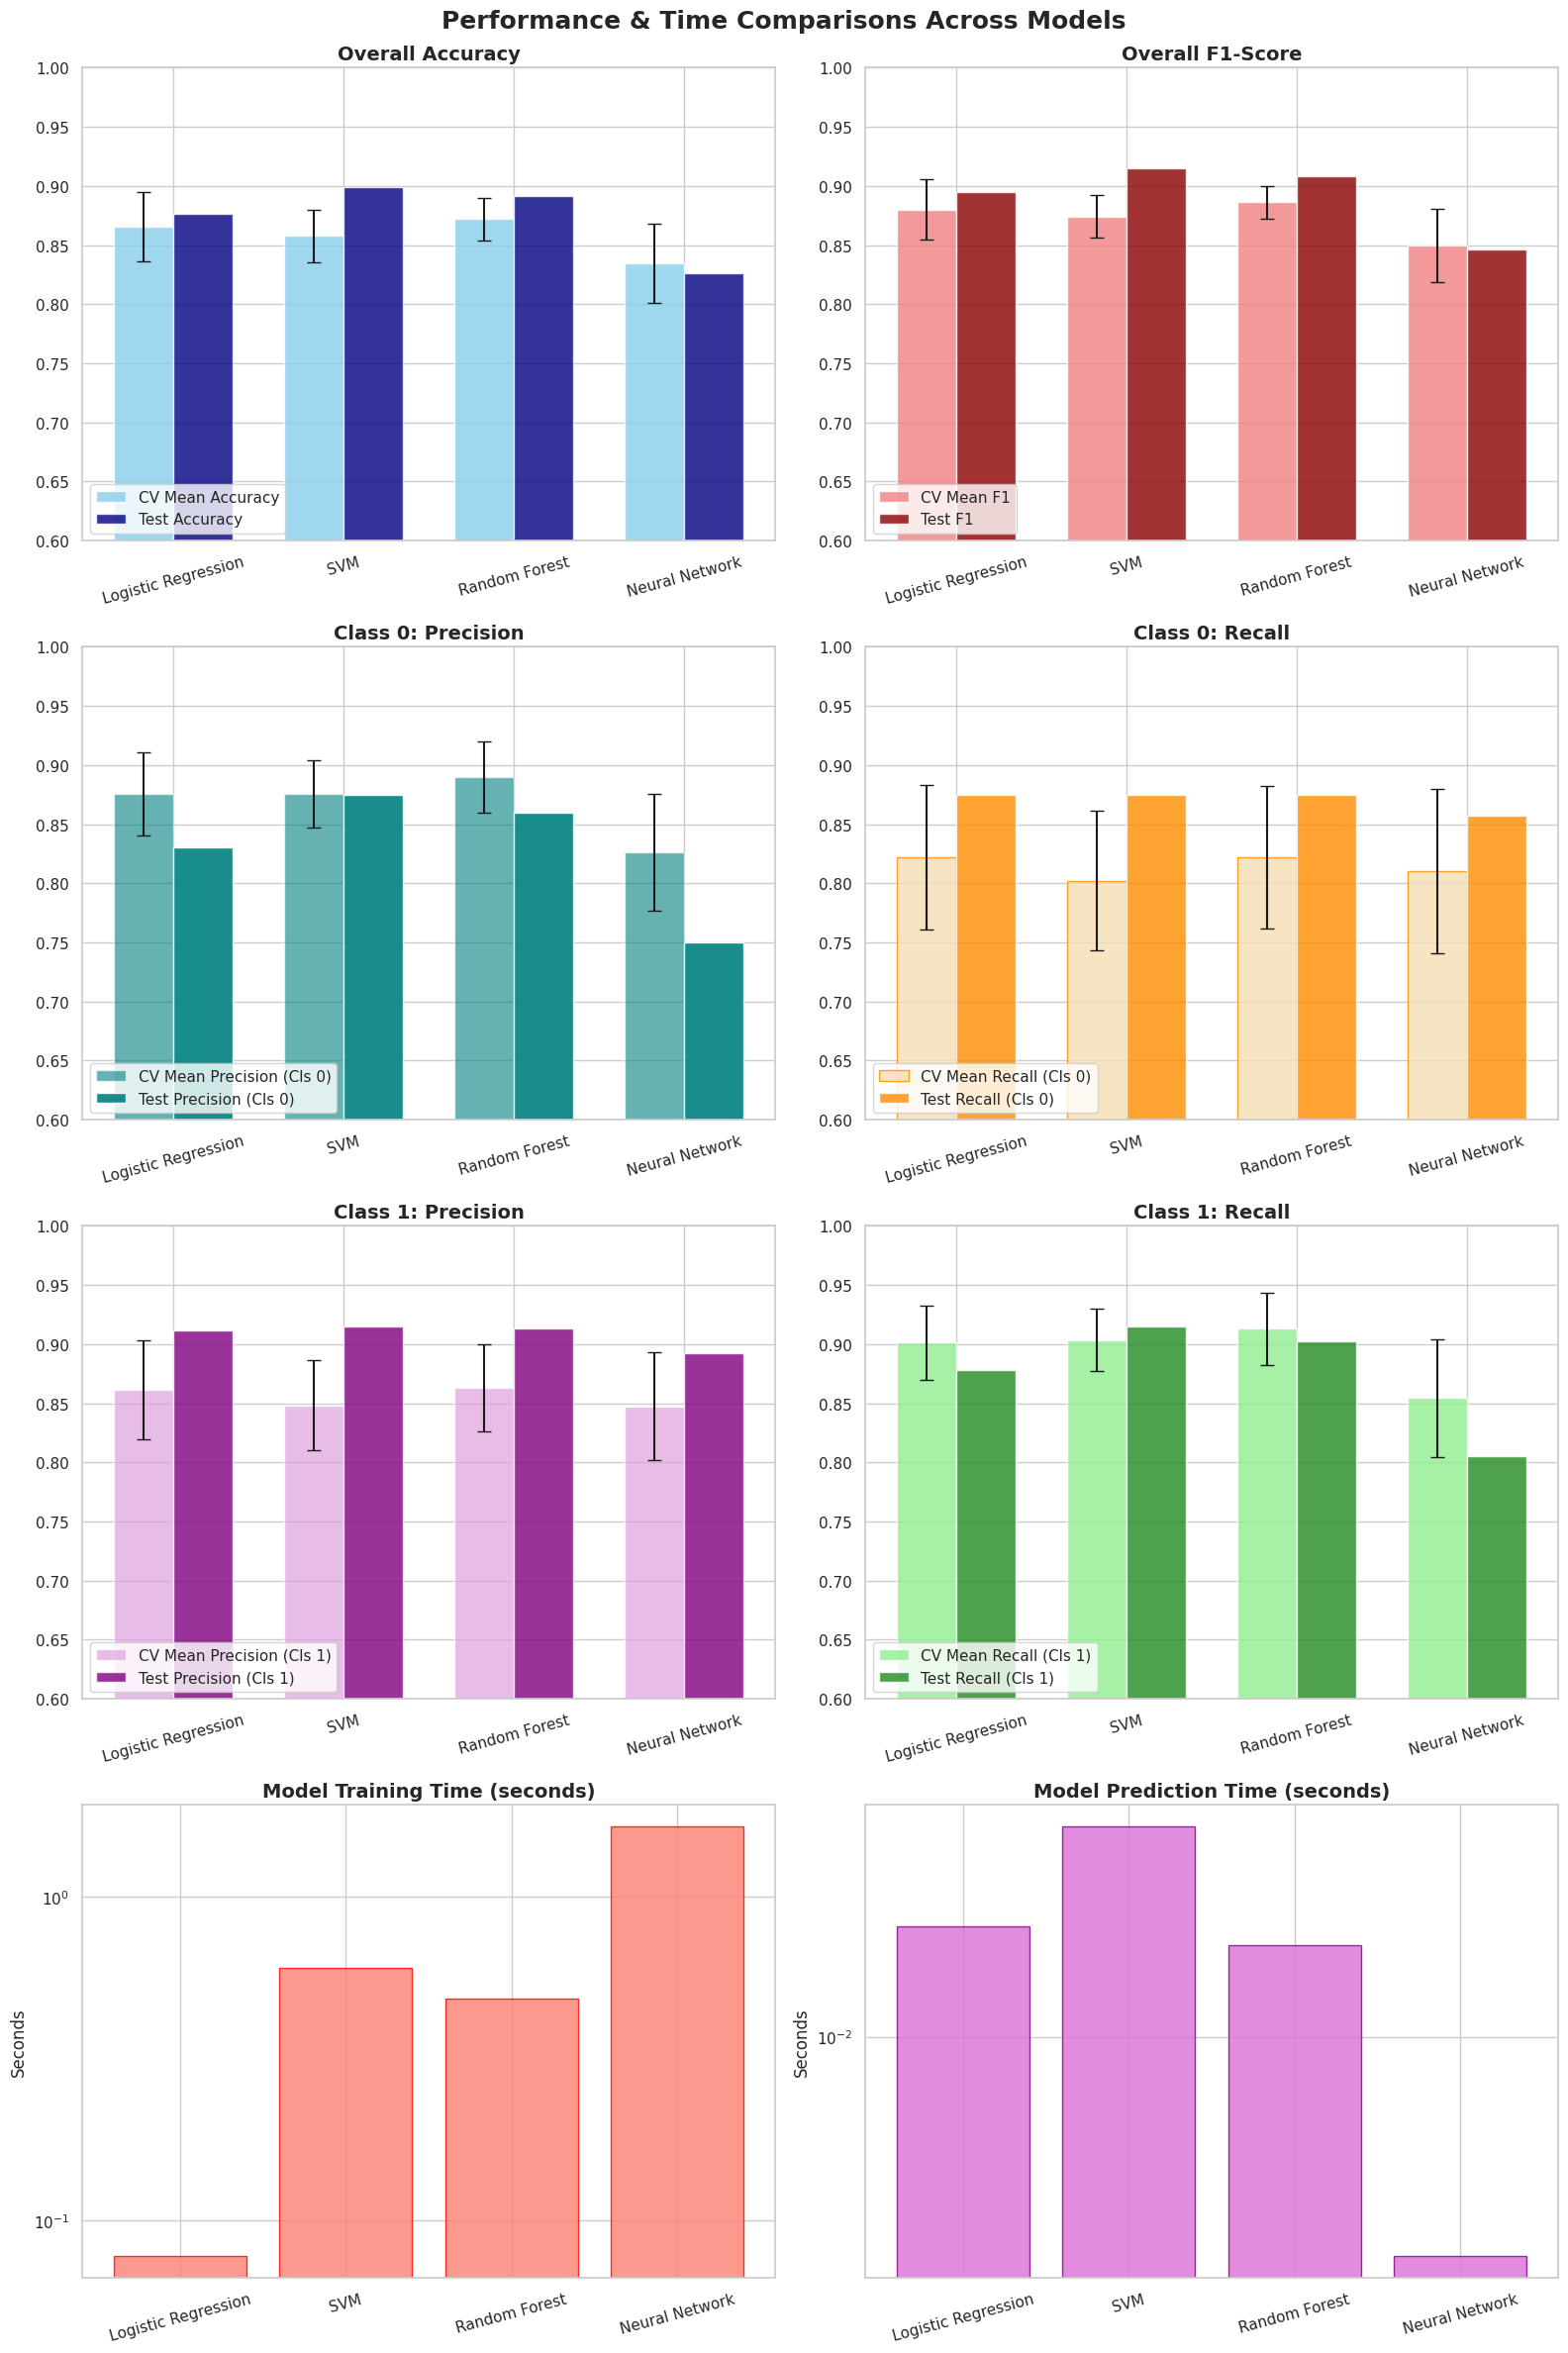

In [ ]:
# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(16, 24))

models = performance_df['Model'].values
x_indices = np.arange(len(models))
bar_width = 0.35

# --- Plot 1: Accuracy Comparison (CV vs Test) ---
axes[0, 0].bar(x_indices - bar_width/2, performance_df['CV_Mean_Accuracy'], bar_width,
               yerr=performance_df['CV_Std_Accuracy'], capsize=5, label='CV Mean Accuracy', color='skyblue', alpha=0.8)
axes[0, 0].bar(x_indices + bar_width/2, performance_df['Test_Accuracy'], bar_width,
               label='Test Accuracy', color='navy', alpha=0.8)
axes[0, 0].set_title('Overall Accuracy', fontsize=14, weight='bold')
axes[0, 0].set_xticks(x_indices)
axes[0, 0].set_xticklabels(models, rotation=15)
axes[0, 0].set_ylim(0.6, 1.0)
axes[0, 0].legend(loc='lower left')

# --- Plot 2: F1-Score Comparison (CV vs Test) ---
axes[0, 1].bar(x_indices - bar_width/2, performance_df['CV_Mean_F1'], bar_width,
               yerr=performance_df['CV_Std_F1'], capsize=5, label='CV Mean F1', color='lightcoral', alpha=0.8)
axes[0, 1].bar(x_indices + bar_width/2, performance_df['Test_F1'], bar_width,
               label='Test F1', color='darkred', alpha=0.8)
axes[0, 1].set_title('Overall F1-Score', fontsize=14, weight='bold')
axes[0, 1].set_xticks(x_indices)
axes[0, 1].set_xticklabels(models, rotation=15)
axes[0, 1].set_ylim(0.6, 1.0)
axes[0, 1].legend(loc='lower left')

# --- Plot 3: Class 0 Precision Comparison (CV vs Test) ---
axes[1, 0].bar(x_indices - bar_width/2, performance_df['CV_Precision_Class_0'], bar_width,
               yerr=performance_df['CV_Std_Precision_Class_0'], capsize=5, label='CV Mean Precision (Cls 0)', color='teal', alpha=0.6)
axes[1, 0].bar(x_indices + bar_width/2, performance_df['Test_Precision_Class_0'], bar_width,
               label='Test Precision (Cls 0)', color='teal', alpha=0.9)
axes[1, 0].set_title('Class 0: Precision', fontsize=14, weight='bold')
axes[1, 0].set_xticks(x_indices)
axes[1, 0].set_xticklabels(models, rotation=15)
axes[1, 0].set_ylim(0.6, 1.0)
axes[1, 0].legend(loc='lower left')

# --- Plot 4: Class 0 Recall Comparison (CV vs Test) ---
axes[1, 1].bar(x_indices - bar_width/2, performance_df['CV_Recall_Class_0'], bar_width,
               yerr=performance_df['CV_Std_Recall_Class_0'], capsize=5, label='CV Mean Recall (Cls 0)', color='wheat', edgecolor='darkorange', alpha=0.8)
axes[1, 1].bar(x_indices + bar_width/2, performance_df['Test_Recall_Class_0'], bar_width,
               label='Test Recall (Cls 0)', color='darkorange', alpha=0.8)
axes[1, 1].set_title('Class 0: Recall', fontsize=14, weight='bold')
axes[1, 1].set_xticks(x_indices)
axes[1, 1].set_xticklabels(models, rotation=15)
axes[1, 1].set_ylim(0.6, 1.0)
axes[1, 1].legend(loc='lower left')

# --- Plot 5: Class 1 Precision Comparison (CV vs Test) ---
axes[2, 0].bar(x_indices - bar_width/2, performance_df['CV_Precision_Class_1'], bar_width,
               yerr=performance_df['CV_Std_Precision_Class_1'], capsize=5, label='CV Mean Precision (Cls 1)', color='plum', alpha=0.7)
axes[2, 0].bar(x_indices + bar_width/2, performance_df['Test_Precision_Class_1'], bar_width,
               label='Test Precision (Cls 1)', color='purple', alpha=0.8)
axes[2, 0].set_title('Class 1: Precision', fontsize=14, weight='bold')
axes[2, 0].set_xticks(x_indices)
axes[2, 0].set_xticklabels(models, rotation=15)
axes[2, 0].set_ylim(0.6, 1.0)
axes[2, 0].legend(loc='lower left')

# --- Plot 6: Class 1 Recall Comparison (CV vs Test) ---
axes[2, 1].bar(x_indices - bar_width/2, performance_df['CV_Recall_Class_1'], bar_width,
               yerr=performance_df['CV_Std_Recall_Class_1'], capsize=5, label='CV Mean Recall (Cls 1)', color='lightgreen', alpha=0.8)
axes[2, 1].bar(x_indices + bar_width/2, performance_df['Test_Recall_Class_1'], bar_width,
               label='Test Recall (Cls 1)', color='forestgreen', alpha=0.8)
axes[2, 1].set_title('Class 1: Recall', fontsize=14, weight='bold')
axes[2, 1].set_xticks(x_indices)
axes[2, 1].set_xticklabels(models, rotation=15)
axes[2, 1].set_ylim(0.6, 1.0)
axes[2, 1].legend(loc='lower left')

# --- Plot 7: Training Time Comparison ---
axes[3, 0].bar(models, performance_df['Train_Time(s)'], color='salmon', alpha=0.8, edgecolor='red')
axes[3, 0].set_title('Model Training Time (seconds)', fontsize=14, weight='bold')
axes[3, 0].set_ylabel('Seconds')
axes[3, 0].set_xticklabels(models, rotation=15)
axes[3, 0].set_yscale('log')

# --- Plot 8: Prediction Time Comparison ---
axes[3, 1].bar(models, performance_df['Predict_Time(s)'], color='orchid', alpha=0.8, edgecolor='purple')
axes[3, 1].set_title('Model Prediction Time (seconds)', fontsize=14, weight='bold')
axes[3, 1].set_ylabel('Seconds')
axes[3, 1].set_xticklabels(models, rotation=15)
axes[3, 1].set_yscale('log')

plt.suptitle('Performance & Time Comparisons Across Models', fontsize=18, weight='bold', y=0.99)
plt.tight_layout()
plt.show()